Dataset Description:
The Titanic Dataset contains information about 891 passengers aboard the RMS Titanic, including details such as age, gender, passenger class, fare, and survival status. It is widely used for Exploratory Data Analysis (EDA) and machine learning to study the factors that influenced passenger survival. The target variable is Survived, where 0 = Did Not Survive and 1 = Survived.

# IMPORT THE LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# DATA COLLECTION

In [2]:
# Load the dataset
df = pd.read_csv("titanic.csv")

# Display the first 5 rows
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


The dataset consists of both numerical and categorical variables. Numerical features include PassengerId, Survived, Pclass, Age, SibSp, Parch, and Fare, while Name, Sex, Ticket, Cabin, and Embarked are categorical variables.

# EXPLORATORY DATA ANALYTICS

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 891
Columns: 12


The Titanic dataset contains 891 rows and 12 columns, indicating that information for 891 passengers is available for analysis.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


To check for the data type of the variables

In [5]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

The dataset initially contains missing values in the Age, Cabin, and Embarked columns. These missing values need to be handled before performing further analysis.

In [6]:
# Removing rows containing missing values

df = df.dropna()

In [7]:
# Checking for missing values after removing them

df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

After removing rows containing missing values, the dataset has no missing values, making it suitable for further exploratory data analysis.

In [8]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,183.000000,183.000000,183.000000,183.000000,183.000000,183.000000,183.000000
mean,455.366120,0.672131,1.191257,35.674426,0.464481,0.475410,78.682469
std,247.052476,0.470725,0.515187,15.643866,0.644159,0.754617,76.347843
min,2.000000,0.000000,1.000000,0.920000,0.000000,0.000000,0.000000
25%,263.500000,0.000000,1.000000,24.000000,0.000000,0.000000,29.700000
50%,457.000000,1.000000,1.000000,36.000000,0.000000,0.000000,57.000000
75%,676.000000,1.000000,1.000000,47.500000,1.000000,1.000000,90.000000
max,890.000000,1.000000,3.000000,80.000000,3.000000,4.000000,512.329200


The summary statistics show that Age ranges from approximately 0.42 to 80 years, while Fare ranges from 0 to 512.33, indicating a large variation in ticket prices. 
The Survived variable is binary, and Third Class (Pclass = 3) contains the highest number of passengers.

In [9]:
from scipy.stats import trim_mean, median_abs_deviation
import pandas as pd
import numpy as np

# Selecting only numerical columns
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

# If PassengerId is not required for analysis, exclude it
numeric_columns = numeric_columns.drop('PassengerId')

for col in numeric_columns:

    summary = pd.DataFrame({

        'Mean': [df[col].mean()],

        'Trimmed Mean': [trim_mean(df[col], 0.10)],

        'Weighted Mean': [np.average(df[col])],

        'Median': [df[col].median()],

        'Minimum': [df[col].min()],

        'Maximum': [df[col].max()],

        'Variance': [df[col].var()],

        'Std Dev': [df[col].std()],

        'Q1': [df[col].quantile(0.25)],

        'Q2': [df[col].quantile(0.50)],

        'Q3': [df[col].quantile(0.75)],

        'IQR': [df[col].quantile(0.75) - df[col].quantile(0.25)],

        '10th Percentile': [df[col].quantile(0.10)],

        '25th Percentile': [df[col].quantile(0.25)],

        '50th Percentile': [df[col].quantile(0.50)],

        '75th Percentile': [df[col].quantile(0.75)],

        '90th Percentile': [df[col].quantile(0.90)],

        'MAD': [median_abs_deviation(df[col], nan_policy='omit')]

    })

    print(f"\nSummary Statistics for {col}\n")
    display(summary)


Summary Statistics for Survived



,Mean,Trimmed Mean,Weighted Mean,Median,Minimum,Maximum,Variance,Std Dev,Q1,Q2,Q3,IQR,10th Percentile,25th Percentile,50th Percentile,75th Percentile,90th Percentile,MAD
0,0.672131,0.714286,0.672131,1.0,0,1,0.221582,0.470725,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0



Summary Statistics for Pclass



,Mean,Trimmed Mean,Weighted Mean,Median,Minimum,Maximum,Variance,Std Dev,Q1,Q2,Q3,IQR,10th Percentile,25th Percentile,50th Percentile,75th Percentile,90th Percentile,MAD
0,1.191257,1.047619,1.191257,1.0,1,3,0.265418,0.515187,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,2.0,0.0



Summary Statistics for Age



,Mean,Trimmed Mean,Weighted Mean,Median,Minimum,Maximum,Variance,Std Dev,Q1,Q2,Q3,IQR,10th Percentile,25th Percentile,50th Percentile,75th Percentile,90th Percentile,MAD
0,35.674426,35.704082,35.674426,36.0,0.92,80.0,244.730542,15.643866,24.0,36.0,47.5,23.5,17.2,24.0,36.0,47.5,56.0,12.0


... (2 outputs left out)


Summary Statistics for Parch



,Mean,Trimmed Mean,Weighted Mean,Median,Minimum,Maximum,Variance,Std Dev,Q1,Q2,Q3,IQR,10th Percentile,25th Percentile,50th Percentile,75th Percentile,90th Percentile,MAD
0,0.47541,0.333333,0.47541,0.0,0,4,0.569447,0.754617,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,2.0,0.0



Summary Statistics for Fare



,Mean,Trimmed Mean,Weighted Mean,Median,Minimum,Maximum,Variance,Std Dev,Q1,Q2,Q3,IQR,10th Percentile,25th Percentile,50th Percentile,75th Percentile,90th Percentile,MAD
0,78.682469,64.767348,78.682469,57.0,0.0,512.3292,5828.993085,76.347843,29.7,57.0,90.0,60.3,13.0,29.7,57.0,90.0,153.4625,29.5


Survived: The mean value indicates that fewer than half of the passengers survived the disaster. Since the variable is binary (0 = Did Not Survive, 1 = Survived), the median and quartiles reflect the predominance of non-survivors in the dataset.

Pclass: The average passenger class is closer to Third Class, indicating that most passengers belonged to the lower travel class. The interquartile range (IQR) shows that the majority of passengers were concentrated in the Second and Third Classes.

Age: The mean and median ages are relatively close, indicating a moderately balanced age distribution after removing missing values. The minimum age is less than one year, while the maximum age is 80 years, showing that the dataset includes passengers ranging from infants to elderly individuals. The IQR indicates that most passengers were adults.

SibSp: The mean is low because the majority of passengers traveled without siblings or spouses. The median value of 0 confirms that at least half of the passengers were traveling alone in terms of siblings or spouses. The higher maximum value indicates that only a few passengers traveled with large families.

Parch: Similar to SibSp, the low mean and median indicate that most passengers did not travel with parents or children. The small IQR further confirms that the majority of observations are concentrated at lower values, while only a few passengers had larger family groups.

Fare: The Fare variable has the largest range and highest variability among all numerical features. The mean is noticeably higher than the median, indicating a positively skewed distribution caused by a small number of passengers paying exceptionally high ticket fares. The large variance, standard deviation, and IQR further confirm the wide spread of fare values.

The descriptive statistics reveal that Fare is the most variable feature in the dataset, whereas SibSp and Parch show limited variability because most passengers traveled with few or no family members. The differences between the mean and median for Fare indicate the presence of high-value outliers, while the remaining numerical variables exhibit relatively stable distributions suitable for further exploratory data analysis.

# CORRELATION MATRIX

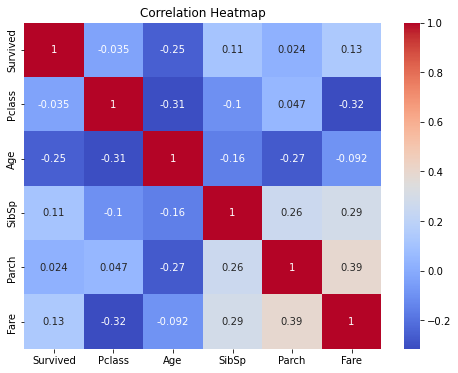

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(
    df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title('Correlation Heatmap')
plt.show()

Fare has a negative correlation with Pclass, indicating that passengers in higher classes generally paid higher fares.

Survived shows a positive correlation with Fare, suggesting that passengers paying higher fares had better survival chances.

Survived has a negative correlation with Pclass, indicating that passengers in First Class had higher survival rates than those in Third Class.

SibSp and Parch show a positive correlation, suggesting that passengers traveling with siblings or spouses often also traveled with parents or children.

Overall, the dataset exhibits weak to moderate correlations, indicating that no single feature alone strongly determines passenger survival.

# BOX PLOT

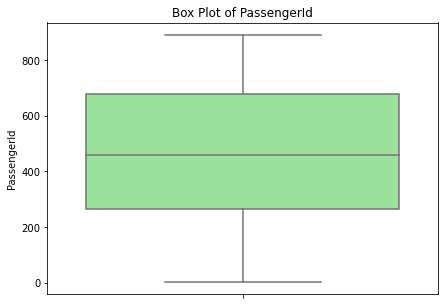


----- PassengerId -----
Minimum Value : 2
Q1 (25%)      : 263.5
Median (Q2)   : 457.0
Q3 (75%)      : 676.0
Maximum Value : 890
IQR           : 412.5
Lower Bound   : -355.25
Upper Bound   : 1294.75
Number of Outliers : 0
--------------------------------------------------


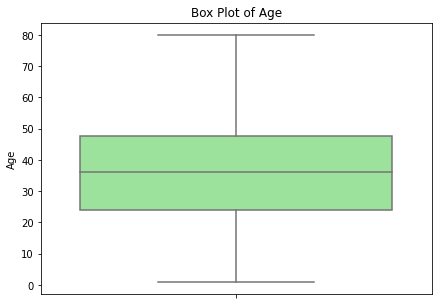


----- Age -----
Minimum Value : 0.92
Q1 (25%)      : 24.0
Median (Q2)   : 36.0
Q3 (75%)      : 47.5
Maximum Value : 80.0
IQR           : 23.5
Lower Bound   : -11.25
Upper Bound   : 82.75
Number of Outliers : 0
--------------------------------------------------


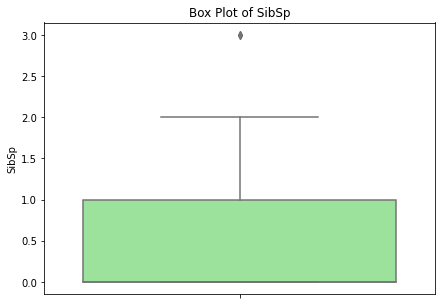


----- SibSp -----
Minimum Value : 0
Q1 (25%)      : 0.0
Median (Q2)   : 0.0
Q3 (75%)      : 1.0
Maximum Value : 3
IQR           : 1.0
Lower Bound   : -1.5
Upper Bound   : 2.5
Number of Outliers : 3
Outlier Values:
[3 3 3]
--------------------------------------------------


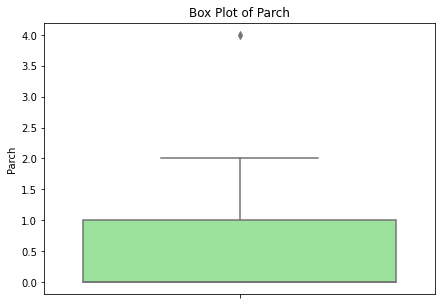


----- Parch -----
Minimum Value : 0
Q1 (25%)      : 0.0
Median (Q2)   : 0.0
Q3 (75%)      : 1.0
Maximum Value : 4
IQR           : 1.0
Lower Bound   : -1.5
Upper Bound   : 2.5
Number of Outliers : 1
Outlier Values:
[4]
--------------------------------------------------


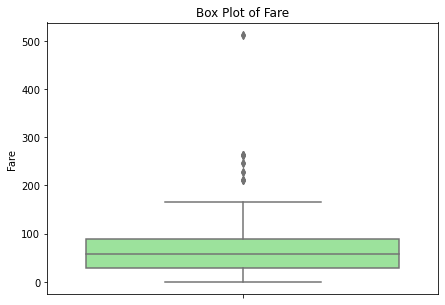


----- Fare -----
Minimum Value : 0.0
Q1 (25%)      : 29.7
Median (Q2)   : 57.0
Q3 (75%)      : 90.0
Maximum Value : 512.3292
IQR           : 60.3
Lower Bound   : -60.749999999999986
Upper Bound   : 180.45
Number of Outliers : 16
Outlier Values:
[263.     263.     247.5208 247.5208 262.375  263.     211.5    263.
 512.3292 211.3375 227.525  227.525  211.3375 512.3292 262.375  211.3375]
--------------------------------------------------


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ['PassengerId', 'Age', 'SibSp', 'Parch', 'Fare']

for col in num_cols:

    # Calculate statistics
    minimum = df[col].min()
    q1 = df[col].quantile(0.25)
    median = df[col].median()
    q3 = df[col].quantile(0.75)
    maximum = df[col].max()
    iqr = q3 - q1

    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]

    # Draw boxplot
    plt.figure(figsize=(7,5))
    sns.boxplot(y=df[col], color='lightgreen')
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)
    plt.show()

    # Print statistics
    print(f"\n----- {col} -----")
    print(f"Minimum Value : {minimum}")
    print(f"Q1 (25%)      : {q1}")
    print(f"Median (Q2)   : {median}")
    print(f"Q3 (75%)      : {q3}")
    print(f"Maximum Value : {maximum}")
    print(f"IQR           : {iqr}")
    print(f"Lower Bound   : {lower_bound}")
    print(f"Upper Bound   : {upper_bound}")
    print(f"Number of Outliers : {len(outliers)}")

    if len(outliers) > 0:
        print("Outlier Values:")
        print(outliers.values)

    print("-"*50)

PassengerId: PassengerId is a sequential identifier and does not exhibit meaningful outliers for analytical purposes.

Age: The Age box plot shows a moderate spread with a few elderly passengers appearing as upper outliers.

SibSp: Most passengers had 0 or 1 sibling/spouse, while a small number of passengers with larger family sizes appear as outliers.

Parch: Most passengers traveled without parents or children, with only a few passengers having high Parch values that appear as outliers.

Fare: The Fare box plot shows several high-value outliers, indicating that a small number of passengers paid significantly higher ticket prices than the majority.


# PAIR PLOT

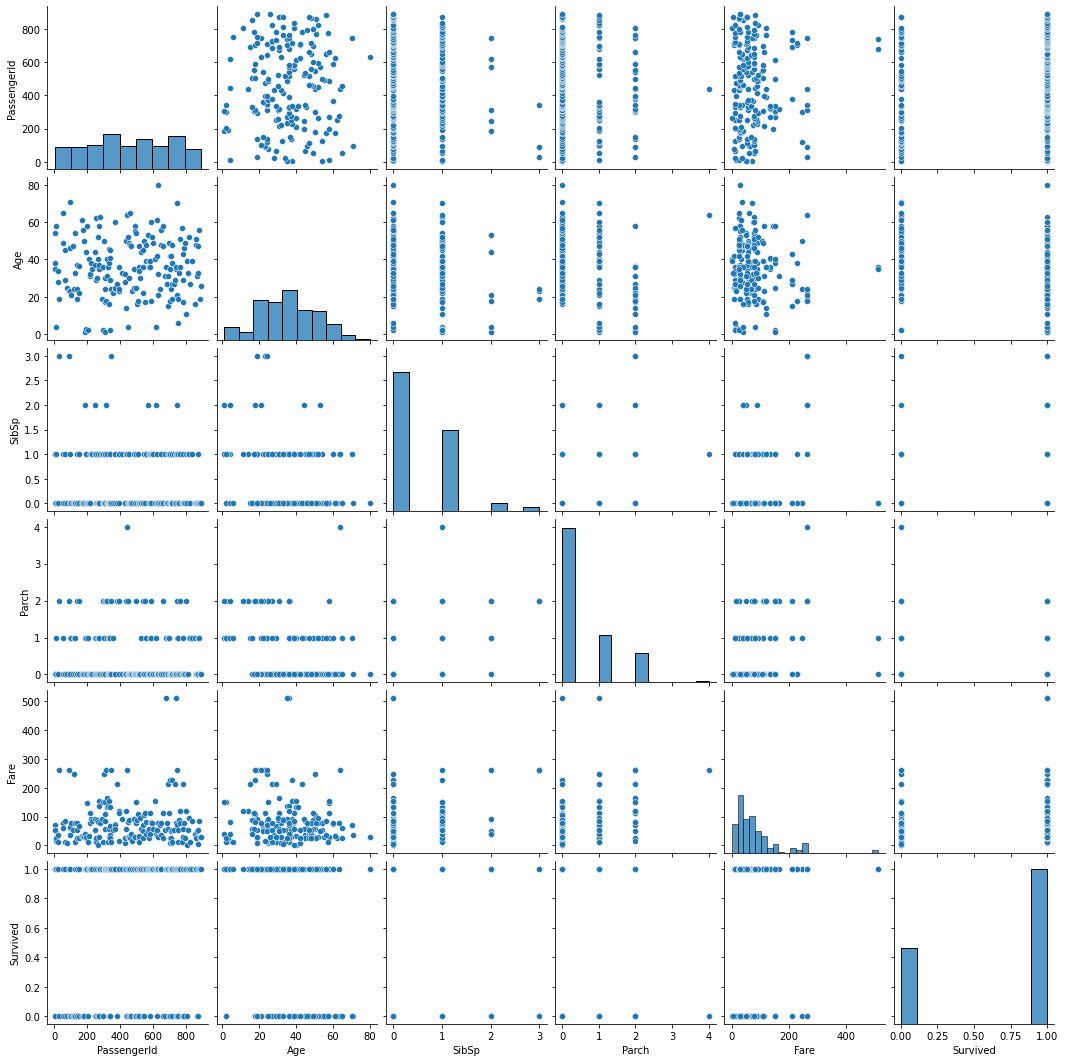

In [12]:
sns.pairplot(df[['PassengerId', 'Age', 'SibSp', 'Parch', 'Fare', 'Survived']])
plt.show()

The pair plot shows that Fare tends to be higher for passengers in First Class (Pclass = 1) than those in Second or Third Class.

Survived exhibits a stronger association with Fare and Pclass, indicating that passengers who paid higher fares and traveled in higher classes had better survival rates.

Age does not show a strong linear relationship with Fare, SibSp, or Parch.

SibSp and Parch display a slight positive relationship, suggesting that passengers traveling with siblings or spouses often also traveled with parents or children.

The diagonal density plots reveal that Fare is highly positively skewed, while Age has a relatively balanced distribution. SibSp and Parch are concentrated at lower values, indicating that most passengers traveled with few or no family members.

Overall, the pair plot suggests that Pclass and Fare are among the most influential numerical features related to passenger survival, whereas the remaining variables exhibit weak to moderate relationships.

# HISTOGRAM

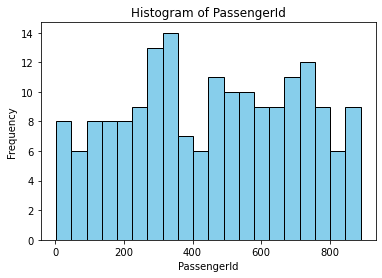

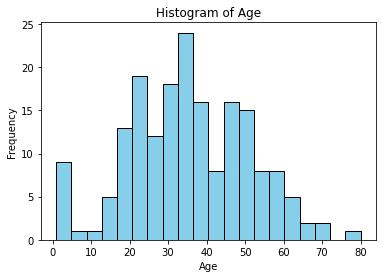

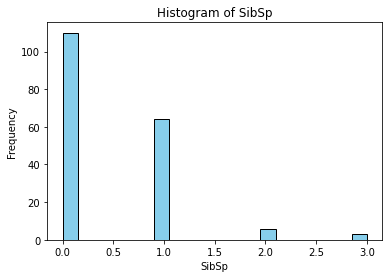

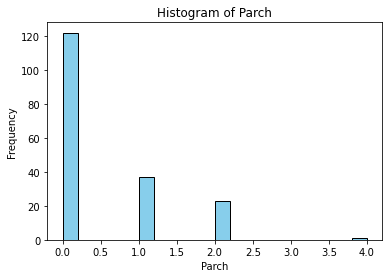

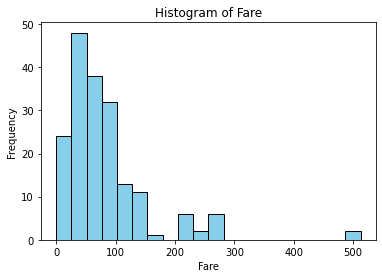

In [13]:
import matplotlib.pyplot as plt

# Numerical columns
num_cols = ['PassengerId', 'Age', 'SibSp', 'Parch', 'Fare']

for col in num_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=20, color='skyblue', edgecolor='black')
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

The histogram shows that most observations are concentrated within a specific range, while a smaller number of observations occur at the extremes.

PassengerId: Passenger IDs are uniformly distributed because they are unique identifiers and do not provide meaningful analytical information.

Survived: More passengers did not survive than survived, indicating that the majority of passengers lost their lives.

Pclass: Most passengers traveled in Third Class, followed by First and Second Class.

Age: Most passengers were between 20 and 40 years old, with relatively few children and elderly passengers.

SibSp: The majority of passengers traveled without siblings or spouses, while only a few traveled with large families.

Parch: Most passengers had no parents or children accompanying them during the journey.

Fare: The Fare distribution is highly right-skewed, with most passengers paying low fares and only a few paying very high fares.

# DENSITY PLOT

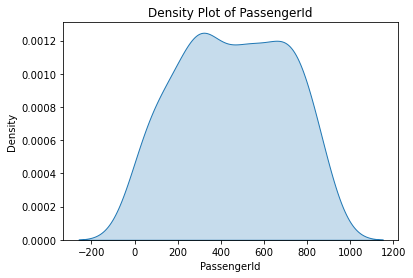

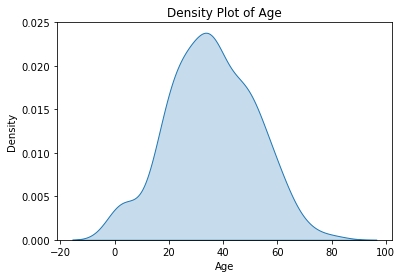

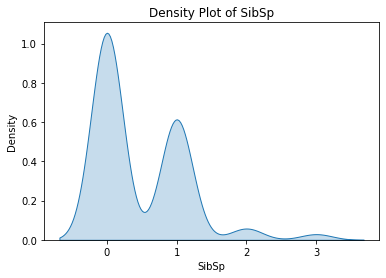

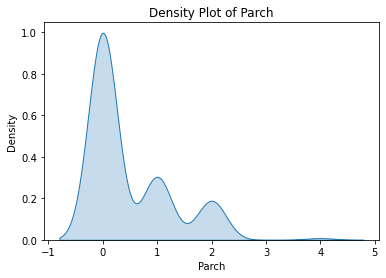

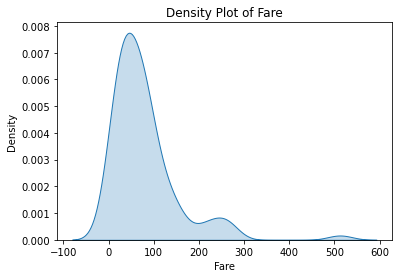

In [14]:
num_cols = ['PassengerId', 'Age', 'SibSp', 'Parch', 'Fare']

for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.kdeplot(df[col], fill=True)
    plt.title(f'Density Plot of {col}')
    plt.show()

PassengerId: The density is nearly uniform because PassengerId is a sequential identifier and does not represent any meaningful distribution.

Age: The density curve shows that most passengers were between 20 and 40 years old, with fewer children and elderly passengers.

SibSp: The density is heavily concentrated at 0, indicating that most passengers traveled without siblings or spouses.

Parch: The density is also concentrated at 0, showing that most passengers traveled without parents or children.

Fare: The density plot is positively (right) skewed, with most passengers paying lower fares and a small number paying exceptionally high fares, resulting in a long right tail.

The density plots indicate that Age has a moderately distributed pattern, while SibSp and Parch are concentrated at lower values. Fare exhibits a strong positive skew due to a few high-priced tickets, whereas PassengerId follows a nearly uniform distribution since it is only a unique identifier.

# SCATTER PLOT

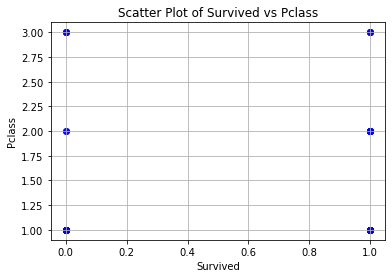

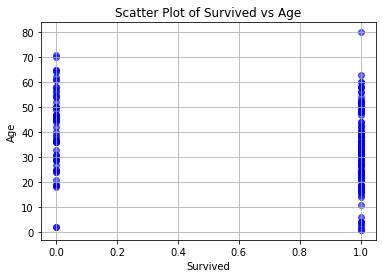

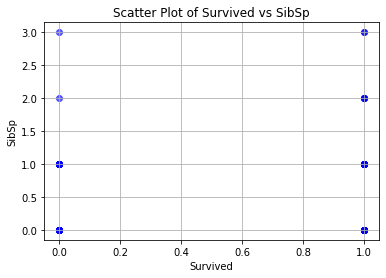

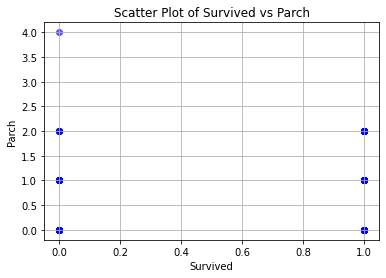

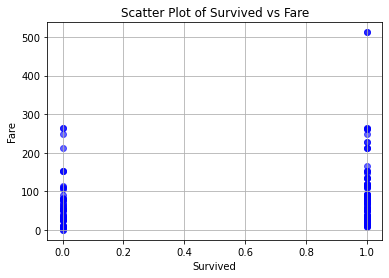

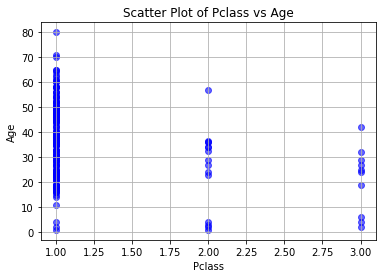

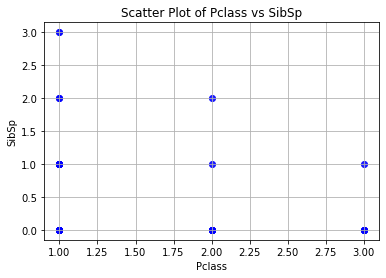

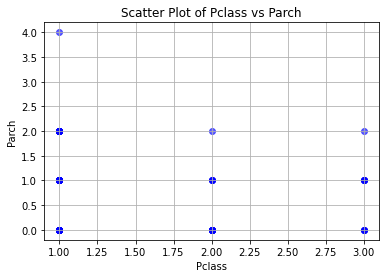

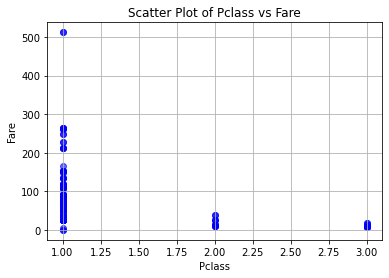

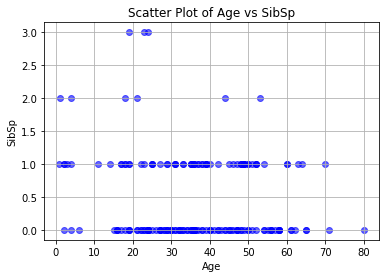

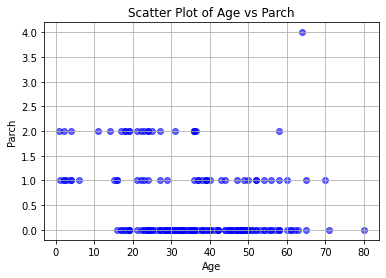

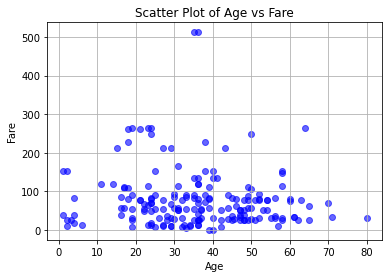

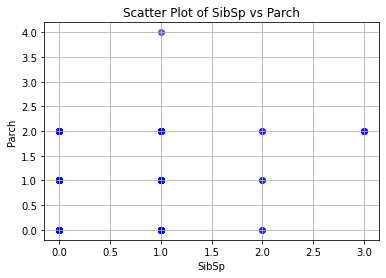

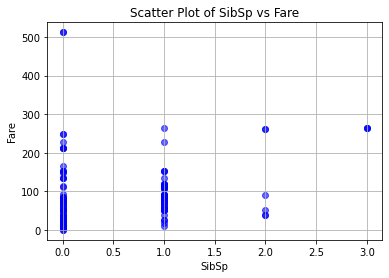

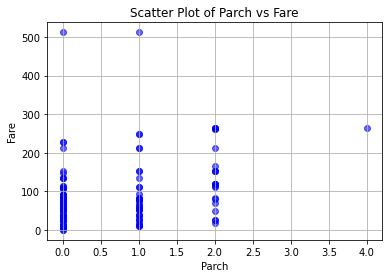

In [15]:
import matplotlib.pyplot as plt

# Selecting only numerical columns
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

# Exclude PassengerId (optional)
numeric_columns = numeric_columns.drop('PassengerId')

# Scatter plots for every pair of numerical features
for i in range(len(numeric_columns)):
    for j in range(i + 1, len(numeric_columns)):

        plt.figure(figsize=(6,4))

        plt.scatter(df[numeric_columns[i]],
                    df[numeric_columns[j]],
                    color='blue',
                    alpha=0.6)

        plt.title(f"Scatter Plot of {numeric_columns[i]} vs {numeric_columns[j]}")
        plt.xlabel(numeric_columns[i])
        plt.ylabel(numeric_columns[j])

        plt.grid(True)
        plt.show()

Survived vs Pclass: Higher survival rates are observed among passengers in First Class, while Third Class passengers show lower survival.

Survived vs Age: Survival is distributed across different age groups, with no strong linear relationship between age and survival.

Survived vs SibSp: Most survivors traveled with either no siblings/spouses or only one, while larger family sizes were less common.

Survived vs Parch: Survival is spread across different Parch values, although most passengers had no accompanying parents or children.

Survived vs Fare: Passengers who paid higher fares generally show a greater likelihood of survival.

Pclass vs Age: Passengers of all age groups are present across all travel classes, indicating no strong relationship between age and passenger class.

Pclass vs SibSp: Most passengers in all classes traveled with small family sizes.

Pclass vs Parch: The majority of passengers across all classes traveled without parents or children.

Pclass vs Fare: Ticket fare decreases as passenger class increases numerically (First Class generally has higher fares than Third Class).

Age vs SibSp: Most passengers with siblings or spouses were adults, with no clear linear relationship between age and SibSp.

Age vs Parch: Younger passengers are more likely to have accompanying parents, while adults generally traveled without parents or children.

Age vs Fare: No significant relationship exists between passenger age and ticket fare.

SibSp vs Parch: Passengers traveling with siblings or spouses often also traveled with parents or children, indicating family groups.

SibSp vs Fare: No strong relationship is observed between family size and ticket fare.

Parch vs Fare: Fare varies across all Parch values, with no clear linear association.

In [16]:
df['Survived'].value_counts()

1    123
0     60
Name: Survived, dtype: int64

The dataset contains more passengers who did not survive (Survived = 0) than passengers who survived (Survived = 1), indicating that the majority of passengers lost their lives during the Titanic disaster.

In [17]:
df.groupby('Survived').mean(numeric_only=True)

,PassengerId,Pclass,Age,SibSp,Parch,Fare
Survived,,,,,,
0,402.983333,1.216667,41.350000,0.366667,0.450000,64.048262
1,480.918699,1.178862,32.905854,0.512195,0.487805,85.821107


Passengers who survived (Survived = 1) generally paid higher average fares and were more likely to belong to higher passenger classes (lower Pclass values) compared to those who did not survive. Survivors also tended to have slightly fewer accompanying family members, indicating that passenger class and ticket fare were important factors influencing survival.

*SUMMARY OF EDA*

The dataset initially contained missing values in the Age, Cabin, and Embarked columns, which were removed before analysis.

The dataset contains both numerical and categorical variables, with Survived serving as the binary target variable.

The statistical summary shows that Fare has the highest variability among all numerical features, while SibSp and Parch have relatively low variability.

Histograms indicate that Age is moderately distributed, whereas Fare is highly positively skewed.

Box plots reveal the presence of several outliers, particularly in the Fare, Age, SibSp, and Parch features.

The dataset contains more passengers who did not survive than those who survived, indicating a moderate class imbalance.

Correlation analysis shows that Fare has a positive relationship with Survived, while Pclass has a negative relationship with Survived, suggesting that passengers in higher classes had better survival rates.

Group-by analysis indicates that passengers who survived generally paid higher fares and belonged to higher passenger classes than those who did not survive.

Most passengers were between 20 and 40 years of age, and the majority traveled without siblings, spouses, parents, or children.

The Titanic dataset is suitable for classification tasks, where the objective is to predict passenger survival based on demographic information, travel class, family relationships, and ticket details.